In [61]:
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_style("whitegrid")
%matplotlib inline
sys.path.append("../")

import warnings

palette = {
    "Não fraude": "#B8DDF2",
    "Fraude": "#F4A7A7",
}

warnings.filterwarnings("ignore")

# Análise Exploratória

Dataset com transações e marcações de fraude de um período de dois anos (2019 e 2020), com dados de:
* lojistas (`store_name` como identificador e `vertical` como segmento)
* clientes (data de nascimento, profissão, cidade e estado; **não há coluna identificadora de cliente**)
* transação (valor, dispositivo, bandeira do cartão)
* geolocalização do lojista e do comprador

## Objetivo do case
Criar um score de risco por transação, considerando os impactos financeiros de cada decisão:
* **Falso Negativo (FN — fraude não detectada):** a transação é aprovada, mas era fraude. Custo = 100% do amount + taxa operacional de chargeback (ex: R$ 15,00).
* **Falso Positivo (FP — cliente legítimo rejeitado):** a transação legítima é bloqueada. Custo = margem financeira perdida (ex: 10% do amount) + custo operacional de análise manual.
* **Verdadeiro Positivo (TP — fraude bloqueada):** fraude evitada com sucesso.
* **Verdadeiro Negativo (TN — venda legítima aprovada):** receita gerada com sucesso.

## Carga e limpeza

In [62]:
raw = pd.read_csv("../data/nuvem_fraud_dataset.csv", delimiter=";")
raw.head()

,created_at,store_name,vertical,amount,device,card_brand,city,state,lat,long,city_population,job,date_of_birth,store_lat,store_long,is_fraud
0,2019-01-01 00:00:44+00:00,"'Heller, Gutmann and Zieme'",grocery_pos,"107,23",Mobile,Master Card,Orient,WA,48|8878,-118|2105,149,'Special educational needs teacher',1978-06-21 00:00:00+00:00,49|159047,-118|186462,0
1,2019-01-01 00:00:51+00:00,'Lind-Buckridge',entertainment,"220,11",Mobile,Amex,Malad City,ID,42|1808,-112|262,4154,'Nature conservation officer',1962-01-19 00:00:00+00:00,43|150704,-112|154481,0
2,2019-01-01 00:07:27+00:00,'Kiehn Inc',grocery_pos,"96,29",Mobile,Amex,Grenada,CA,41|6125,-122|5258,589,'Systems analyst',1945-12-21 00:00:00+00:00,41|65752,-122|230347,0
3,2019-01-01 00:09:03+00:00,'Beier-Hyatt',shopping_pos,"7,77",Mobile,Visa,High Rolls Mountain Park,NM,32|9396,-105|8189,899,'Naval architect',1967-08-30 00:00:00+00:00,32|863258,-106|520205,0
4,2019-01-01 00:21:32+00:00,'Bruen-Yost',misc_pos,"6,85",Web,Master Card,Freedom,WY,43|0172,-111|0292,471,"'Education officer, museum'",1967-08-02 00:00:00+00:00,43|753735,-111|454923,0


In [63]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 341519 entries, 0 to 341518
Data columns (total 16 columns):
 #   Column           Non-Null Count   Dtype
---  ------           --------------   -----
 0   created_at       341519 non-null  str  
 1   store_name       341519 non-null  str  
 2   vertical         341519 non-null  str  
 3   amount           341519 non-null  str  
 4   device           341519 non-null  str  
 5   card_brand       341519 non-null  str  
 6   city             341519 non-null  str  
 7   state            340576 non-null  str  
 8   lat              341308 non-null  str  
 9   long             341197 non-null  str  
 10  city_population  341519 non-null  int64
 11  job              341519 non-null  str  
 12  date_of_birth    341519 non-null  str  
 13  store_lat        341519 non-null  str  
 14  store_long       341519 non-null  str  
 15  is_fraud         341519 non-null  int64
dtypes: int64(2), str(14)
memory usage: 95.1 MB


In [64]:
n_duplicates = raw.duplicated().sum()
print(f"Foram encontradas {n_duplicates} entradas duplicadas no dataset")
raw = raw.drop_duplicates()

Foram encontradas 1912 entradas duplicadas no dataset


Há entradas duplicadas na base (cerca de 0,5% das observações), removidas antes das análises.

Há também valores ausentes em campos do cliente: estado cadastrado e geolocalização.

A partir da data da transação (`created_at`) são criadas as colunas de safra (`cohort`, mensal) e de dia (`day`), usadas nas análises temporais e na separação das bases de modelagem.

Também são convertidas as colunas numéricas de valor e de coordenadas (separador decimal `,` e `|`).

In [65]:
raw['amount'] = pd.to_numeric(raw["amount"].astype(str).str.replace(",", ".", regex=False))
raw['created_at'] = pd.to_datetime(raw["created_at"])

raw["cohort"] = raw["created_at"].dt.to_period('M')
raw["day"] = raw["created_at"].dt.to_period('D')

raw['date_of_birth'] = pd.to_datetime(raw["date_of_birth"])

for col in ['lat', 'long', 'store_lat', 'store_long']:
    raw[col] = raw[col].str.replace('|', '.').astype(float)

Cria-se um id único para cada transação, a partir do dataset ordenado por data.

In [66]:
raw = raw.reset_index(drop=True)
raw["row_orig"] = raw.index
raw = raw.sort_values(["created_at", "row_orig"]).reset_index(drop=True).drop(["row_orig"], axis=1)
raw["txn_id"] = raw.index
raw.head()

,created_at,store_name,vertical,amount,device,card_brand,city,state,lat,long,city_population,job,date_of_birth,store_lat,store_long,is_fraud,cohort,day,txn_id
0,2019-01-01 00:00:44+00:00,"'Heller, Gutmann and Zieme'",grocery_pos,107.23,Mobile,Master Card,Orient,WA,48.8878,-118.2105,149,'Special educational needs teacher',1978-06-21 00:00:00+00:00,49.159047,-118.186462,0,2019-01,2019-01-01,0
1,2019-01-01 00:00:51+00:00,'Lind-Buckridge',entertainment,220.11,Mobile,Amex,Malad City,ID,42.1808,-112.2620,4154,'Nature conservation officer',1962-01-19 00:00:00+00:00,43.150704,-112.154481,0,2019-01,2019-01-01,1
2,2019-01-01 00:07:27+00:00,'Kiehn Inc',grocery_pos,96.29,Mobile,Amex,Grenada,CA,41.6125,-122.5258,589,'Systems analyst',1945-12-21 00:00:00+00:00,41.657520,-122.230347,0,2019-01,2019-01-01,2
3,2019-01-01 00:09:03+00:00,'Beier-Hyatt',shopping_pos,7.77,Mobile,Visa,High Rolls Mountain Park,NM,32.9396,-105.8189,899,'Naval architect',1967-08-30 00:00:00+00:00,32.863258,-106.520205,0,2019-01,2019-01-01,3
4,2019-01-01 00:21:32+00:00,'Bruen-Yost',misc_pos,6.85,Web,Master Card,Freedom,WY,43.0172,-111.0292,471,"'Education officer, museum'",1967-08-02 00:00:00+00:00,43.753735,-111.454923,0,2019-01,2019-01-01,4


## Dados ausentes

Um pequeno volume de transações (menos de 0,1% da base) não tem geolocalização do cliente. Elas se concentram em dias específicos e nenhuma foi marcada como fraude.

In [67]:
sem_coordenadas = raw[raw[["lat", "long"]].isna().any(axis=1)]

sem_coordenadas.groupby("day")["is_fraud"].agg(["mean", "count"])

,mean,count
day,,
2019-03-29,0.0,31
2019-09-25,0.0,29
2020-02-11,0.0,17
2020-05-30,0.0,260
2020-09-04,0.0,147
2020-12-21,0.0,16


O campo `state` ausente mostra um padrão mais interessante: também se concentra em dias específicos, mas em alguns deles há volume relevante de fraude.

In [68]:
sem_estado = raw[raw["state"].isna()]

sem_estado.groupby("day")["is_fraud"].agg(["mean", "count"])

,mean,count
day,,
2019-02-28,0.000000,151
2019-03-01,0.035088,57
2019-09-15,0.000000,35
2019-12-23,0.017995,389
2019-12-24,0.010909,275
2020-12-31,0.000000,36


---

## Evolução temporal

A taxa média de fraude no período é de cerca de 0,5% das transações, com perda média em torno de R$ 39 mil por mês.

A perda é máxima no início do período e cai abruptamente no fim do primeiro semestre de 2019, com leve aumento em agosto de 2019. A mesma oscilação se repete entre o fim de 2019 e o início de 2020, provavelmente por atualização das políticas de prevenção, seguida de mudança do modus operandi dos fraudadores e novos ajustes de regras.

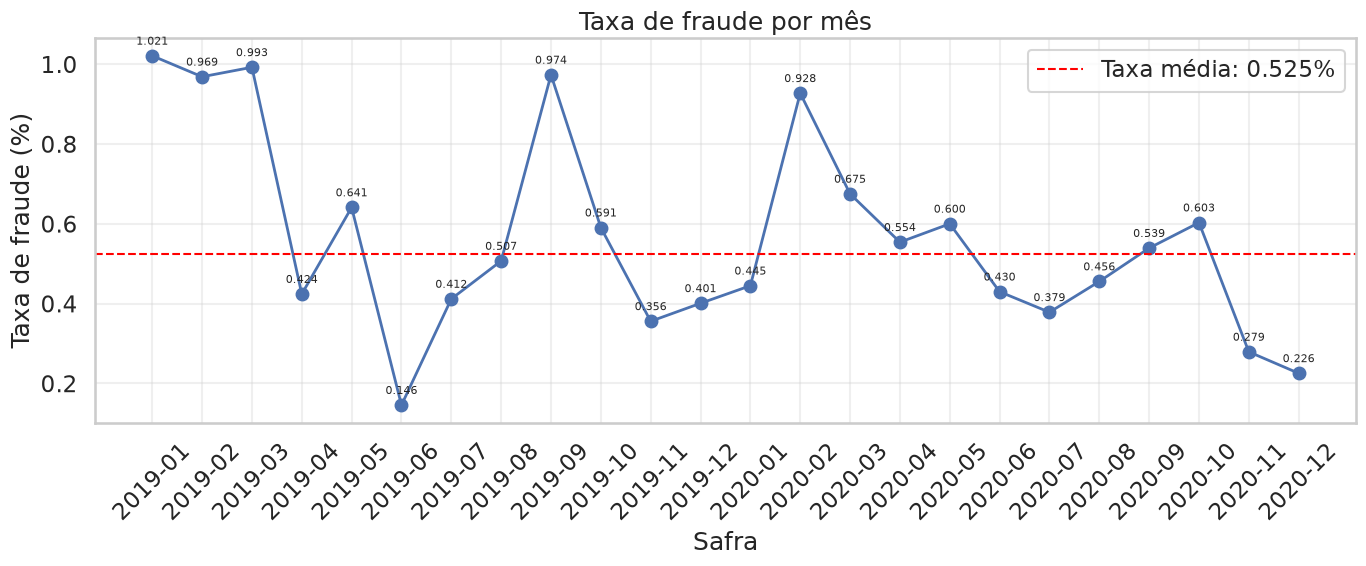

In [69]:
monthly_fraud = raw.groupby("cohort")["is_fraud"].mean().sort_index() * 100
overall_fraud_rate = raw["is_fraud"].mean() * 100

x = monthly_fraud.index.astype(str).tolist()
y = monthly_fraud.to_numpy(dtype=float)

fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(x, y, marker="o", linewidth=2)

for i, (month, rate) in enumerate(monthly_fraud.items()):
    ax.annotate(
        f"{rate:.3f}",
        (x[i], float(rate)),
        textcoords="offset points",
        xytext=(0, 8),
        ha="center",
        fontsize=8,
    )

ax.set_title("Taxa de fraude por mês")
ax.set_xlabel("Safra")
ax.set_ylabel("Taxa de fraude (%)")
ax.axhline(
    overall_fraud_rate,
    color="red",
    linestyle="--",
    linewidth=1.5,
    label=f"Taxa média: {overall_fraud_rate:.3f}%",
)
ax.legend(loc="upper right")
ax.tick_params(axis="x", rotation=45)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

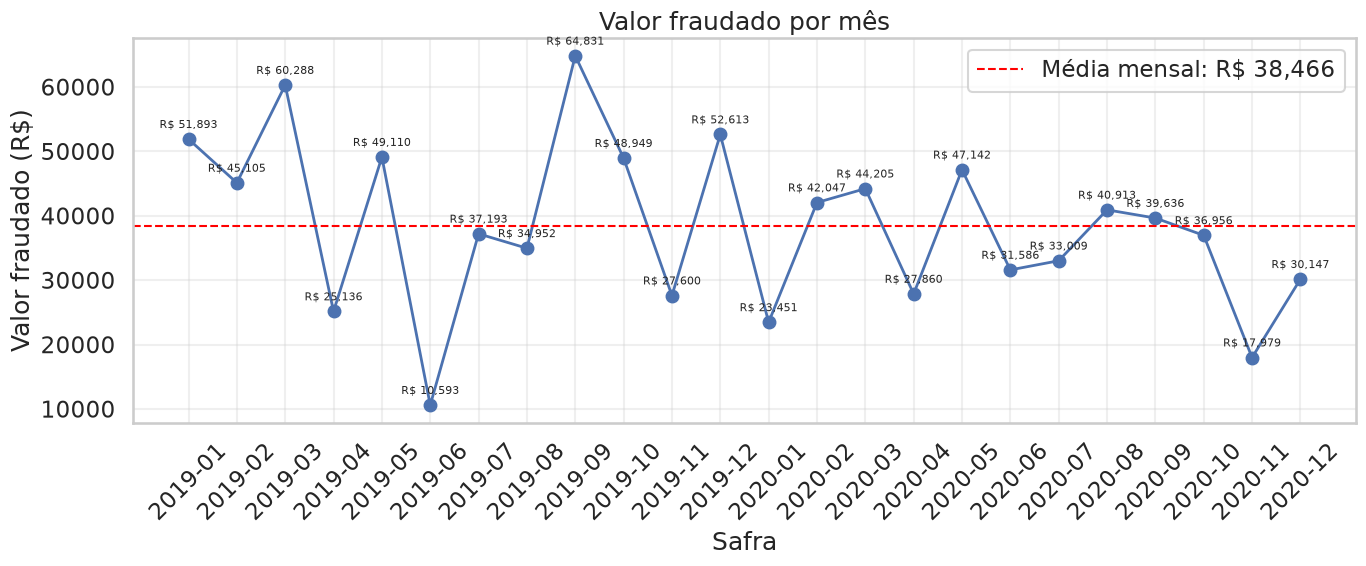

In [70]:
monthly_fraud_amount = (
    raw.loc[raw["is_fraud"].eq(1)]
    .groupby("cohort")["amount"]
    .sum()
    .reindex(monthly_fraud.index, fill_value=0)
)

average_monthly_fraud_amount = monthly_fraud_amount.mean()
x = monthly_fraud_amount.index.astype(str).tolist()
y = monthly_fraud_amount.to_numpy(dtype=float)

fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(x, y, marker="o", linewidth=2)

for i, amount in enumerate(y):
    ax.annotate(
        f"R$ {amount:,.0f}",
        (x[i], amount),
        textcoords="offset points",
        xytext=(0, 8),
        ha="center",
        fontsize=8,
    )

ax.set_title("Valor fraudado por mês")
ax.set_xlabel("Safra")
ax.set_ylabel("Valor fraudado (R$)")
ax.axhline(
    average_monthly_fraud_amount,
    color="red",
    linestyle="--",
    linewidth=1.5,
    label=f"Média mensal: R$ {average_monthly_fraud_amount:,.0f}",
)
ax.legend(loc="upper right")
ax.tick_params(axis="x", rotation=45)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

---

A seguir são analisadas as variáveis do dataset e sua relação com o target. A função abaixo calcula, por categoria, volume, taxa de fraude, lift, weight of evidence (WoE) e information value (IV), e é usada ao longo de toda a análise.

In [71]:
def iv_woe_category(
    df: pd.DataFrame,
    category: str,
    target: str = "is_fraud",
) -> pd.DataFrame:
    """
    Calcula IV, WoE, fraud rate e lift por categoria.

    Target:
        0 = Não fraude
        1 = Fraude
    """
    aux = (
        df.groupby([category, target], dropna=False)
        .size()
        .unstack(fill_value=0)
        .reindex(columns=[0, 1], fill_value=0)
    )

    aux = aux.rename(columns={
        0: "n_legit",
        1: "n_fraud",
    })

    # Volume e taxa de fraude
    aux["n_txns"] = aux["n_legit"] + aux["n_fraud"]
    aux["pct_population"] = aux["n_txns"] / len(df)

    aux["fraud_rate"] = (
        aux["n_fraud"] / aux["n_txns"]
    )

    base_rate = df[target].mean()

    aux["lift"] = (
        aux["fraud_rate"] / base_rate
        if base_rate > 0 else np.nan
    )

    # Distribuições para WoE / IV
    # Smoothing para evitar log(0)
    eps = 0.5

    n_categories = len(aux)

    dist_fraud = (
        (aux["n_fraud"] + eps)
        / (aux["n_fraud"].sum() + eps * n_categories)
    )

    dist_legit = (
        (aux["n_legit"] + eps)
        / (aux["n_legit"].sum() + eps * n_categories)
    )

    aux["WOE"] = np.log(dist_fraud / dist_legit)

    aux["IV"] = (
        (dist_fraud - dist_legit) * aux["WOE"]
    )

    return aux.sort_values("lift", ascending=False)


---

## Valor transacionado

O valor da transação separa bem fraudes de legítimas: as legítimas são majoritariamente de baixo valor, enquanto cerca de 75% das fraudes têm valor acima de R$ 200.

Um corte seco nesse valor, porém, também pegaria um volume significativo de transações legítimas de alto valor, gerando impacto e fricção com a base de lojistas.

Descritiva do valor na base toda:

In [72]:
raw['amount'].describe()


count    339607.000000
mean         70.577984
std         161.675242
min           1.000000
25%           9.600000
50%          46.460000
75%          83.350000
max       28948.900000
Name: amount, dtype: float64

Separando fraudes e legítimas, com percentis na cauda superior. Há uma transação legítima atípica, acima de R$ 20.000:

In [73]:
raw.loc[raw['amount']>20000]

,created_at,store_name,vertical,amount,device,card_brand,city,state,lat,long,city_population,job,date_of_birth,store_lat,store_long,is_fraud,cohort,day,txn_id
144783,2019-12-01 16:19:23+00:00,'Satterfield-Lowe',travel,28948.9,Mobile,Master Card,Westerville,NE,41.4193,-99.3844,73,'Product designer',1935-02-10 00:00:00+00:00,42.317313,-99.139498,0,2019-12,2019-12-01,144783


In [74]:
amount_describe = (
    raw.groupby("is_fraud")["amount"]
    .describe(percentiles=[0.25, 0.50, 0.75, 0.95, 0.99, 0.995, 0.999])
    .rename(index={0: "Não fraude", 1: "Fraude"})
)

amount_describe

,count,mean,std,min,25%,50%,75%,95%,99%,99.5%,99.9%,max
is_fraud,,,,,,,,,,,,
Não fraude,337825.0,68.217523,156.251647,1.00,9.5700,46.250,82.760,193.1460,489.6128,681.08640,1593.11480,28948.90
Fraude,1782.0,518.065460,389.627409,1.78,214.6775,356.435,884.725,1084.5975,1176.2429,1210.14555,1319.12652,1371.81


Simulando uma política simples (bloquear transações acima de R$ 200), detecta-se cerca de 75% das fraudes do histórico, mas com alto impacto em receita: cerca de R$ 6 milhões em transações legítimas bloqueadas no acumulado.

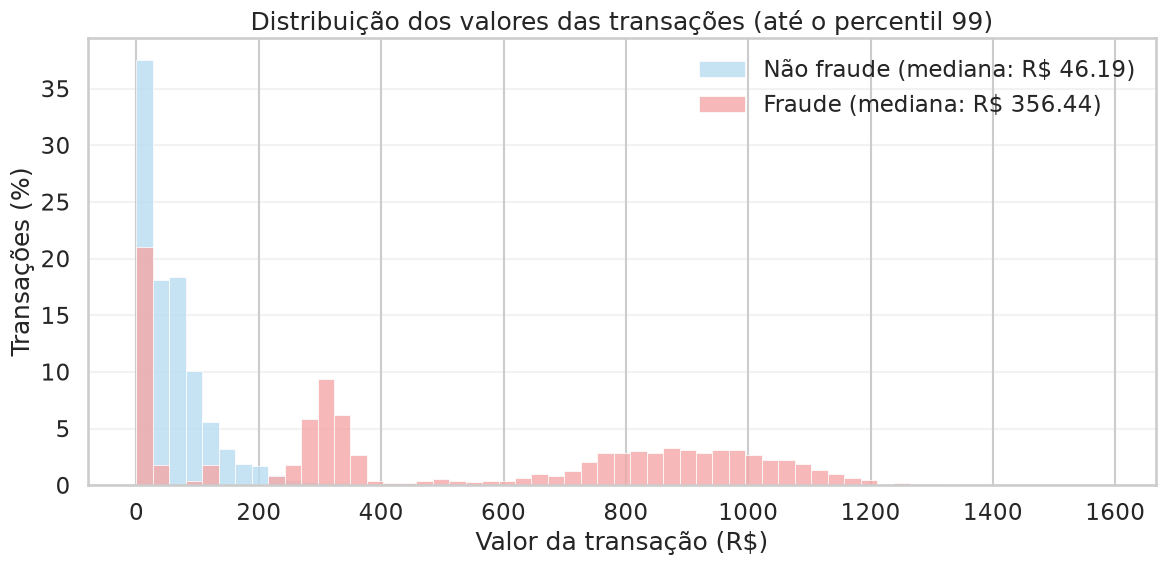

In [75]:
amount_upper = raw["amount"].quantile(0.999)
amount_bins = np.linspace(0, amount_upper, 60)

fig, ax = plt.subplots(figsize=(12, 6))

for fraud_value, label in [(0, "Não fraude"), (1, "Fraude")]:
    values = raw.loc[
        raw["is_fraud"].eq(fraud_value) & raw["amount"].le(amount_upper),
        "amount",
    ]
    median_value = values.median()

    sns.histplot(
        x=values,
        bins=amount_bins,
        stat="percent",
        color=palette[label],
        alpha=0.8,
        edgecolor="white",
        linewidth=0.5,
        label=f"{label} (mediana: R$ {median_value:.2f})",
        ax=ax,
    )

ax.set_title("Distribuição dos valores das transações (até o percentil 99)")
ax.set_xlabel("Valor da transação (R$)")
ax.set_ylabel("Transações (%)")
ax.grid(axis="y", alpha=0.25)
ax.legend(frameon=False)

plt.tight_layout()
plt.show()

Simulando uma política simples (bloquear transações acima de R$ 200), detecta-se cerca de 75% da fraude observada no histórico de dois anos, mas com um impacto significativo na perda de margem  (6 milhões em receita de transações legítimas bloqueadas)

In [76]:
raw["high_amount"] = np.where(raw["amount"] > 200, 1, 0)

In [77]:
pd.crosstab(
    index=raw["high_amount"],
    columns=raw["is_fraud"],
    values=raw["amount"],
    aggfunc="sum",
    margins=True,
    margins_name="Total",
).rename_axis(index="high_amount", columns="is_fraud")

is_fraud,0,1,Total
high_amount,,,
0,16424899.47,11550.03,16436449.5
1,6620685.28,911642.62,7532327.9
Total,23045584.75,923192.65,23968777.4


In [78]:
pd.crosstab(
    index=raw["high_amount"],
    columns=raw["is_fraud"],
    values=raw["txn_id"],
    aggfunc="count",
    margins=True,
    margins_name="Total",
).rename_axis(index="high_amount", columns="is_fraud")

is_fraud,0,1,Total
high_amount,,,
0,322469,444,322913
1,15356,1338,16694
Total,337825,1782,339607


In [79]:
recall_high_amount = raw.loc[raw["is_fraud"].eq(1), "high_amount"].mean()
print(f"Fraudes com amount > 200: {recall_high_amount:.1%}")

Fraudes com amount > 200: 75.1%


Para fins ilustrativos, calcula-se o IV da variavel 'high amount' na base histórica, e nota-se que de fato, esse corte possui alto poder discriminante. usaraemos essa variável como ponto de partida na construção do score de risco. Com mais variáveis a serem consideradas, espera-se uma redução considerável da proporção de falsos positivos.

In [80]:
iv_woe_category(raw, 'high_amount', 'is_fraud')

is_fraud,n_legit,n_fraud,n_txns,pct_population,fraud_rate,lift,WOE,IV
high_amount,,,,,,,,
1,15356,1338,16694,0.049157,0.080149,15.274417,2.804244,1.977677
0,322469,444,322913,0.950843,0.001375,0.262039,-1.342580,0.946847


---

## Hora da transação

A taxa de fraude varia muito ao longo do dia: entre 22h e 3h ela fica bem acima da média; no restante do dia, bem abaixo. O horário está em UTC, como em `created_at`.

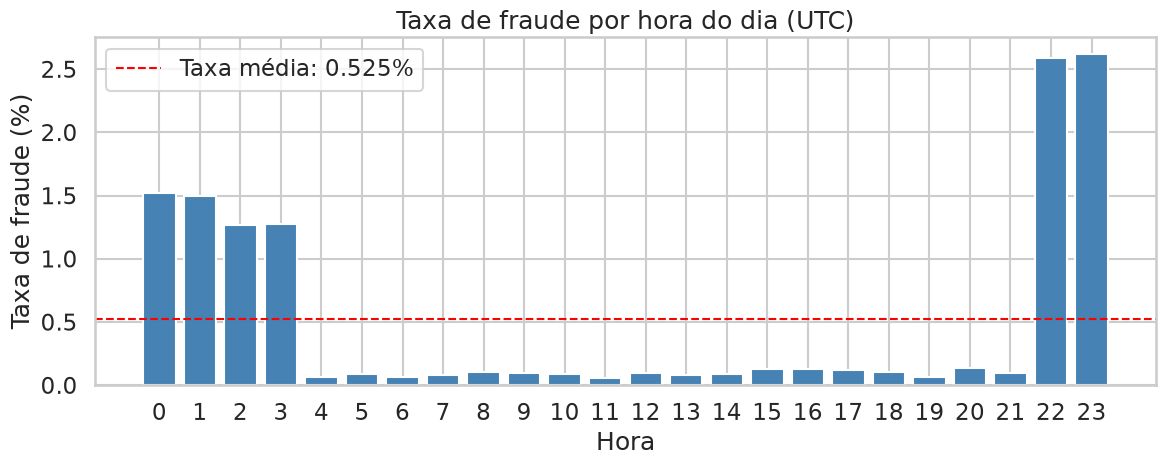

In [81]:
raw["hour"] = raw["created_at"].dt.hour

fraud_by_hour = raw.groupby("hour")["is_fraud"].mean() * 100

fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(fraud_by_hour.index, fraud_by_hour.to_numpy(), color="steelblue")
ax.axhline(overall_fraud_rate, color="red", linestyle="--", linewidth=1.5,
           label=f"Taxa média: {overall_fraud_rate:.3f}%")
ax.set_xticks(range(24))
ax.set_title("Taxa de fraude por hora do dia (UTC)")
ax.set_xlabel("Hora")
ax.set_ylabel("Taxa de fraude (%)")
ax.legend()
plt.tight_layout()
plt.show()

In [82]:
raw["night"] = np.where(raw["hour"].isin([22, 23, 0, 1, 2, 3]), 1, 0)
iv_woe_category(raw, "night", "is_fraud")

is_fraud,n_legit,n_fraud,n_txns,pct_population,fraud_rate,lift,WOE,IV
night,,,,,,,,
1,77972,1530,79502,0.2341,0.019245,3.667603,1.313472,0.824306
0,259853,252,260105,0.7659,0.000969,0.184638,-1.692228,1.062005


---

## Vertical

Entre os 14 segmentos de lojistas (`vertical`), destacam-se três grupos:

* **Alto risco:** shopping_net, grocery_pos, misc_net
* **Médio risco:** shopping_pos, gas_transport, travel, misc_pos
* **Baixo risco:** demais



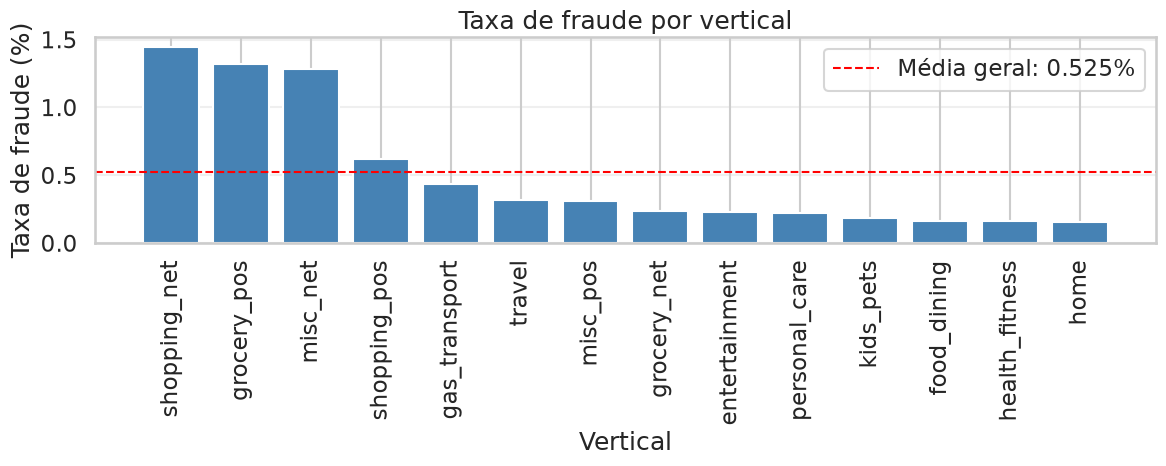

In [83]:
fraud_by_vertical = raw.groupby("vertical")["is_fraud"].mean() * 100
overall_fraud_rate_pct = raw["is_fraud"].mean() * 100

fig, ax = plt.subplots(figsize=(12, 5))
fraud_by_vertical = (
    raw.groupby("vertical")["is_fraud"]
    .mean()
    .sort_values(ascending=False)
    * 100
)

x = fraud_by_vertical.index.to_list()
y = fraud_by_vertical.to_numpy(dtype=float)
ax.bar(x, y, color="steelblue")
ax.axhline(
    overall_fraud_rate_pct,
    color="red",
    linestyle="--",
    linewidth=1.5,
    label=f"Média geral: {overall_fraud_rate_pct:.3f}%",
)

ax.set_title("Taxa de fraude por vertical")
ax.set_xlabel("Vertical")
ax.set_ylabel("Taxa de fraude (%)")
ax.tick_params(axis="x", rotation=90)
ax.legend()
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

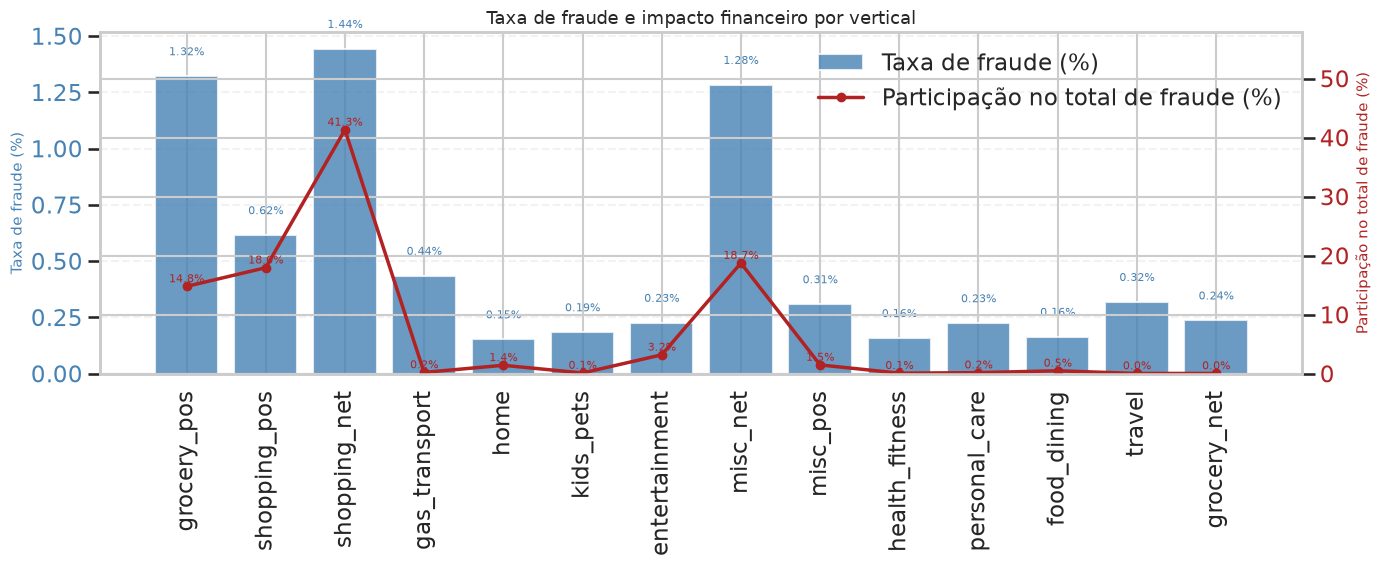

,vertical,n_txns,n_fraud,fraud_rate_pct,fraud_amount,fraud_amount_rate_of_vertical_pct,fraud_amount_share_of_total_fraud_pct
0,shopping_net,26379,381,1.444331,381430.20,16.673317,41.316425
1,misc_net,16898,217,1.284176,172983.82,12.760443,18.737565
2,shopping_pos,30329,187,0.616572,165742.81,6.835917,17.953220
3,grocery_pos,32732,433,1.322864,136494.18,3.346059,14.785016
4,entertainment,24222,55,0.227066,29452.99,1.914033,3.190341
5,misc_pos,20024,62,0.309628,13653.11,1.100249,1.478902
6,home,32516,50,0.153770,13073.58,0.704527,1.416127
7,food_dining,23038,38,0.164945,4456.39,0.381766,0.482715
8,gas_transport,35089,153,0.436034,1934.87,0.087893,0.209585
9,personal_care,24406,55,0.225354,1592.39,0.133813,0.172487


In [84]:
summary = (
    raw.assign(fraud_amount=raw["amount"].where(raw["is_fraud"].eq(1), 0))
    .groupby("vertical", as_index=False)
    .agg(
        n_txns=("is_fraud", "size"),
        total_amount=("amount", "sum"),
        n_fraud=("is_fraud", "sum"),
        fraud_amount=("fraud_amount", "sum"),
    )
)

summary["fraud_rate"] = summary["n_fraud"] / summary["n_txns"]
summary["fraud_amount_rate_of_vertical"] = (
    summary["fraud_amount"] / summary["total_amount"]
)
summary["fraud_amount_share_of_total_fraud"] = (
    summary["fraud_amount"] / summary["fraud_amount"].sum()
)
summary["fraud_rate_pct"] = summary["fraud_rate"] * 100
summary["fraud_amount_rate_of_vertical_pct"] = summary["fraud_amount_rate_of_vertical"] * 100
summary["fraud_amount_share_of_total_fraud_pct"] = summary["fraud_amount_share_of_total_fraud"] * 100

# Tabela resumida de perda por vertical
loss_rank = (
    summary[
        [
            "vertical",
            "n_txns",
            "n_fraud",
            "fraud_rate_pct",
            "fraud_amount",
            "fraud_amount_rate_of_vertical_pct",
            "fraud_amount_share_of_total_fraud_pct",
        ]
    ]
    .sort_values("fraud_amount", ascending=False)
    .reset_index(drop=True)
)
# Ordena o gráfico pelo maior volume total e mantém a tabela de perda por fraude em ordem de valor fraudado
summary = summary.sort_values("total_amount", ascending=False).reset_index(drop=True)

loss_rank = (
    summary[
        [
            "vertical",
            "n_txns",
            "n_fraud",
            "fraud_rate_pct",
            "fraud_amount",
            "fraud_amount_rate_of_vertical_pct",
            "fraud_amount_share_of_total_fraud_pct",
        ]
    ]
    .sort_values("fraud_amount", ascending=False)
    .reset_index(drop=True)
)

# Combinação das duas visões: taxa de fraude e participação na perda total
fig, ax1 = plt.subplots(figsize=(14, 6))

bars = ax1.bar(
    summary["vertical"],
    summary["fraud_rate_pct"],
    color="steelblue",
    alpha=0.8,
    width=0.8,
    label="Taxa de fraude (%)",
)

ax1.set_ylabel("Taxa de fraude (%)", color="steelblue", fontsize=11)
ax1.tick_params(axis="y", labelcolor="steelblue")
ax1.tick_params(axis="x", rotation=90)
ax1.grid(axis="y", linestyle="--", alpha=0.25)
ax1.set_title("Taxa de fraude e impacto financeiro por vertical", fontsize=13)

ax2 = ax1.twinx()
line, = ax2.plot(
    summary["vertical"],
    summary["fraud_amount_share_of_total_fraud_pct"],
    color="firebrick",
    marker="o",
    linewidth=2.5,
    markersize=6,
    label="Participação no total de fraude (%)",
)
ax2.set_ylabel("Participação no total de fraude (%)", color="firebrick", fontsize=11)
ax2.tick_params(axis="y", labelcolor="firebrick")
ax2.set_ylim(0, max(summary["fraud_amount_share_of_total_fraud_pct"].max() * 1.4, 5))

# Anotações
for bar, rate in zip(bars, summary["fraud_rate_pct"]):
    ax1.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.08,
        f"{rate:.2f}%",
        ha="center",
        va="bottom",
        fontsize=8,
        color="steelblue",
    )

for x, loss_pct in zip(summary["vertical"], summary["fraud_amount_share_of_total_fraud_pct"]):
    ax2.text(
        x,
        loss_pct + 0.25,
        f"{loss_pct:.1f}%",
        ha="center",
        va="bottom",
        fontsize=8,
        color="firebrick",
    )

# Legendas combinadas
handles1, labels1 = ax1.get_legend_handles_labels()
handles2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(handles1 + handles2, labels1 + labels2, loc="upper right", frameon=False)

plt.tight_layout()
plt.show()

# Resumo em tabela: top verticais por valor fraudado
loss_rank.head(10)

In [85]:
iv_woe_category(raw, 'vertical', 'is_fraud')

is_fraud,n_legit,n_fraud,n_txns,pct_population,fraud_rate,lift,WOE,IV
vertical,,,,,,,,
shopping_net,25998,381,26379,0.077675,0.014443,2.752552,1.019209,0.138909
grocery_pos,32299,433,32732,0.096382,0.013229,2.521066,0.929977,0.136433
misc_net,16681,217,16898,0.049758,0.012842,2.447335,0.901035,0.065053
shopping_pos,30142,187,30329,0.089306,0.006166,1.175039,0.160979,0.002509
gas_transport,34936,153,35089,0.103322,0.004360,0.830978,-0.186695,0.003288
travel,10289,33,10322,0.030394,0.003197,0.609283,-0.486442,0.005707
misc_pos,19962,62,20024,0.058962,0.003096,0.590078,-0.525552,0.012694
grocery_net,11328,27,11355,0.033436,0.002378,0.453154,-0.779999,0.014166
entertainment,24167,55,24222,0.071324,0.002271,0.432735,-0.835489,0.033849


In [86]:
RISK_VERTICALS = ['shopping_net', 'grocery_pos', 'misc_net', 'shopping_pos']

raw['risk_vertical'] = np.where(raw['vertical'].isin(RISK_VERTICALS), 1, 0)

In [87]:
iv_woe_category(raw, 'risk_vertical', 'is_fraud')

is_fraud,n_legit,n_fraud,n_txns,pct_population,fraud_rate,lift,WOE,IV
risk_vertical,,,,,,,,
1,105120,1218,106338,0.313121,0.011454,2.182869,0.786747,0.292852
0,232705,564,233269,0.686879,0.002418,0.460777,-0.777355,0.289356


---

## Device

Há duas categorias de device (`Web` e `Mobile`), ambas com taxa de fraude em torno de 0,5%, igual à média histórica, e IV praticamente nulo. A variável não será usada no score.

In [88]:
device_iv_woe = iv_woe_category(raw, 'device', 'is_fraud')
device_iv_woe.sort_values('WOE', ascending=False)

is_fraud,n_legit,n_fraud,n_txns,pct_population,fraud_rate,lift,WOE,IV
device,,,,,,,,
Web,112964,604,113568,0.33441,0.005318,1.013561,0.013806,0.000064
Mobile,224861,1178,226039,0.66559,0.005211,0.993187,-0.007009,0.000033


---

## Bandeira do cartão

Também não há diferença relevante entre as bandeiras (Visa, Mastercard e Amex): as três têm taxa de fraude próxima à média do período. A variável não será usada no score.

In [89]:
bandeira_iv_woe = iv_woe_category(raw, 'card_brand', 'is_fraud')
bandeira_iv_woe.sort_values('WOE', ascending=False)

is_fraud,n_legit,n_fraud,n_txns,pct_population,fraud_rate,lift,WOE,IV
card_brand,,,,,,,,
Master Card,112738,605,113343,0.333748,0.005338,1.017254,0.017183,0.000099
Visa,168636,902,169538,0.499218,0.005320,1.013931,0.013623,0.000093
Amex,56451,275,56726,0.167034,0.004848,0.923888,-0.078595,0.000993


---

## Estado

O estado ausente e `AK` têm risco maior que os demais, mas ambos são pouco representativos (em torno de 1% da base).

In [90]:
state_iv_woe = iv_woe_category(raw.assign(state=raw["state"].fillna("missing")), "state", "is_fraud")
state_iv_woe.sort_values("WOE", ascending=False).head(10)

is_fraud,n_legit,n_fraud,n_txns,pct_population,fraud_rate,lift,WOE,IV
state,,,,,,,,
AK,2903,50,2953,0.008695,0.016932,3.226826,1.189193,0.023348
missing,931,12,943,0.002777,0.012725,2.425149,0.929824,0.003933
OR,26128,197,26325,0.077516,0.007483,1.426155,0.355849,0.011763
NE,34116,216,34332,0.101093,0.006292,1.199012,0.180946,0.003624
CO,19590,115,19705,0.058023,0.005836,1.112219,0.107362,0.000706
NM,23222,121,23343,0.068735,0.005184,0.987865,-0.012071,0.000010
CA,79883,402,80285,0.236406,0.005007,0.954246,-0.049738,0.000571
WA,26835,126,26961,0.079389,0.004673,0.890643,-0.116347,0.001015
MO,54514,253,54767,0.161266,0.004620,0.880381,-0.129966,0.002556


---

## Idade do cliente

In [91]:
raw["age"] = (
    raw["created_at"].dt.year
    - raw["date_of_birth"].dt.year
    - (
        (raw["created_at"].dt.month < raw["date_of_birth"].dt.month)
        | (
            (raw["created_at"].dt.month == raw["date_of_birth"].dt.month)
            & (raw["created_at"].dt.day < raw["date_of_birth"].dt.day)
        )
    ).astype(int)
)

In [92]:
age_describe = (
    raw.groupby("is_fraud")["age"]
    .describe(percentiles=[0.25, 0.50, 0.75, 0.95, 0.99, 0.995, 0.999])
    .rename(index={0: "Não fraude", 1: "Fraude"})
)

age_describe

,count,mean,std,min,25%,50%,75%,95%,99%,99.5%,99.9%,max
is_fraud,,,,,,,,,,,,
Não fraude,337825.0,47.281968,17.014444,17.0,34.0,45.0,58.0,83.0,91.0,92.0,93.0,93.0
Fraude,1782.0,50.241863,18.312141,19.0,35.0,50.0,63.0,83.0,91.0,91.0,91.0,91.0


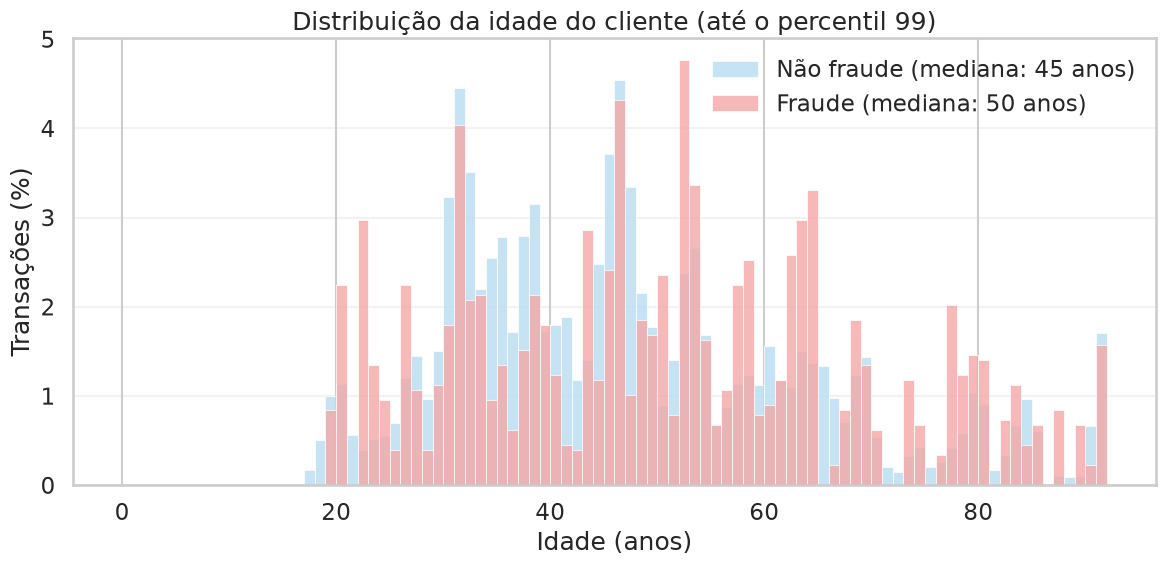

In [93]:
upper = int(np.ceil(raw["age"].quantile(0.99)))
bins = np.arange(0, upper + 2)

fig, ax = plt.subplots(figsize=(12, 6))

for fraud_value, label in [(0, "Não fraude"), (1, "Fraude")]:
    ages = raw.loc[raw["is_fraud"].eq(fraud_value), "age"].dropna()
    median_age = ages.median()

    sns.histplot(
        x=ages,
        bins=bins,
        stat="percent",
        color=palette[label],
        alpha=0.8,
        edgecolor="white",
        linewidth=0.5,
        label=f"{label} (mediana: {median_age:.0f} anos)",
        ax=ax,
    )

ax.set_title("Distribuição da idade do cliente (até o percentil 99)")
ax.set_xlabel("Idade (anos)")
ax.set_ylabel("Transações (%)")
ax.grid(axis="y", alpha=0.25)
ax.legend(frameon=False)

plt.tight_layout()
plt.show()

In [94]:
raw.groupby("age")["is_fraud"].agg(
    n_txns="count",
    n_frauds="sum",
    fraud_rate="mean"
).sort_values(by='fraud_rate', ascending=False).head()

,n_txns,n_frauds,fraud_rate
age,,,
87,368,15,0.040761
22,1375,53,0.038545
89,365,12,0.032877
77,1443,36,0.024948
73,1108,21,0.018953


As distribuições de idade de fraudes e legítimas são parecidas (mediana de 50 contra 45 anos), mas algumas idades específicas concentram taxas de fraude muito acima da média. 

---

## Distância cliente–lojista

In [95]:
def haversine(lat1, lon1, lat2, lon2):
    R = 6371.0

    lat1, lon1, lat2, lon2 = map(
        np.radians, (lat1, lon1, lat2, lon2)
    )

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        np.sin(dlat / 2) ** 2
        + np.cos(lat1) * np.cos(lat2)
        * np.sin(dlon / 2) ** 2
    )

    return 2 * R * np.arcsin(np.sqrt(np.clip(a, 0, 1)))

raw["distance_km"] = haversine(
    raw["lat"],
    raw["long"],
    raw["store_lat"],
    raw["store_long"]
)

In [96]:
distance_describe = (
    raw.groupby("is_fraud")["distance_km"]
    .describe(percentiles=[0.25, 0.50, 0.75, 0.95, 0.99, 0.995, 0.999])
    .rename(index={0: "Não fraude", 1: "Fraude"})
)

distance_describe

,count,mean,std,min,25%,50%,75%,95%,99%,99.5%,99.9%,max
is_fraud,,,,,,,,,,,,
Não fraude,337325.0,75.575632,29.057432,0.205072,54.725475,77.614035,97.951126,119.894983,131.258064,134.254957,138.788536,152.117173
Fraude,1782.0,75.573043,28.483529,1.449529,55.755169,77.364438,96.948835,118.558580,131.830803,135.682310,140.166512,142.484909


A distância entre cliente e lojista tem distribuição praticamente idêntica entre fraudes e legítimas e não será usada. Como mostrado adiante, as coordenadas do lojista variam dentro de uma mesma loja, o que reforça que esse dado não é confiável.

---

## Resolução de identidades

Informação **por cliente** é um fator importante para o score antifraude. Como o dataset **não tem identificador de cliente**, constrói-se um **identificador proxy** a partir de data de nascimento, profissão e cidade. Com isso são identificados **187 clientes únicos**, operando em **700 lojistas**.

Esse identificador permite construir variáveis transacionais a partir do histórico de cada cliente.

Para uso em produção, as features devem ser construídas sobre `customer_id` e `store_id` reais.

In [97]:
raw["customer_id"] = raw.groupby(
    ["date_of_birth", "job", "city"],
    dropna=False
).ngroup()

raw['customer_id'].nunique()

187

In [98]:
customer_fraud_labels = (
    raw.groupby("customer_id")
    .agg(
        n_transactions=("txn_id", "count"),
        n_fraud_transactions=("is_fraud", "sum"),
    )
    .reset_index()
)

customer_fraud_labels["fraud_transaction_pct"] = (
    100 * customer_fraud_labels["n_fraud_transactions"]
    / customer_fraud_labels["n_transactions"]
)



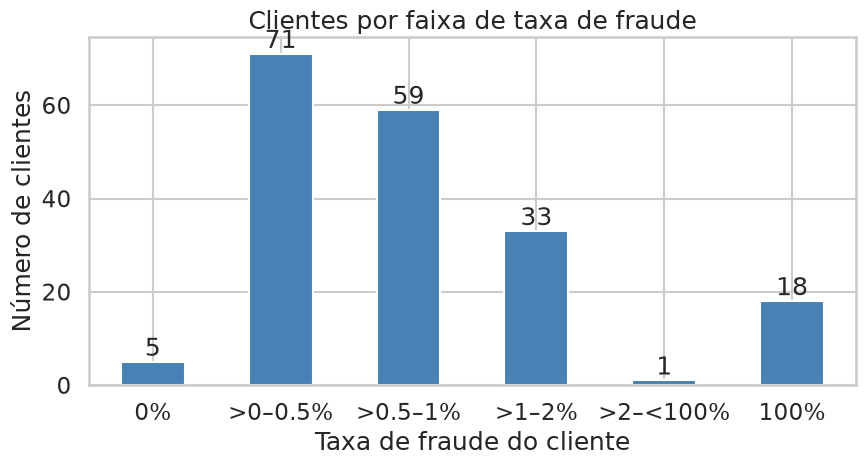

In [99]:
fraud_pct = customer_fraud_labels["fraud_transaction_pct"]

bins = [
    "0%",
    ">0–0.5%",
    ">0.5–1%",
    ">1–2%",
    ">2–<100%",
    "100%",
]

conditions = [
    fraud_pct.eq(0),
    fraud_pct.gt(0) & fraud_pct.le(0.5),
    fraud_pct.gt(0.5) & fraud_pct.le(1),
    fraud_pct.gt(1) & fraud_pct.le(2),
    fraud_pct.gt(2) & fraud_pct.lt(100),
    fraud_pct.eq(100),
]

customer_bins = pd.Series(
    np.select(conditions, bins, default="Other"),
    index=customer_fraud_labels.index,
)

counts = customer_bins.value_counts().reindex(bins, fill_value=0)

ax = counts.plot(kind="bar", figsize=(9, 5), color="steelblue")
ax.set_title("Clientes por faixa de taxa de fraude")
ax.set_xlabel("Taxa de fraude do cliente")
ax.set_ylabel("Número de clientes")
ax.bar_label(ax.containers[0])
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Há 7 casos em que o mesmo `store_name` aparece com mais de uma `vertical`. Assume-se que são canais distintos do mesmo vendedor (físico e online), **então o `store_id` é construído com a chave composta** (`store_name`, `vertical`).

In [100]:
inconsistent_stores = (
    raw.groupby(["store_name", "vertical"], dropna=False)
    .size()
    .rename("row_count")
    .reset_index()
    .groupby("store_name")["vertical"]
    .nunique()
    .loc[lambda s: s > 1]
    .index
)

pair_counts = (
    raw.groupby(["store_name", "vertical"], dropna=False)
    .size()
    .rename("row_count")
    .reset_index()
)

pair_counts[pair_counts["store_name"].isin(inconsistent_stores)] \
    .sort_values(["store_name", "vertical"])

,store_name,vertical,row_count
70,'Boyer PLC',misc_pos,370
71,'Boyer PLC',shopping_net,499
106,'Cormier LLC',health_fitness,464
107,'Cormier LLC',shopping_net,521
138,'Dickinson Lt',misc_pos,407
139,'Dickinson Lt',personal_care,484
194,'Gislason Group',misc_pos,440
195,'Gislason Group',travel,211
320,'Kilback LLC',food_dining,441
321,'Kilback LLC',grocery_pos,708


In [101]:
raw["store_id"] = raw.groupby(
    ["store_name", "vertical"],
    dropna=False
).ngroup()

raw['store_id'].nunique()

700

As coordenadas do lojista (`store_lat`, `store_long`) variam dentro de um mesmo `store_id`, o que indica que **não representam de forma confiável a localização do ponto de venda**. Por isso não são usadas aqui. Em uma versão produtiva, valeria incorporar features de IP e geolocalização do cliente e o match com os dados cadastrais.

In [102]:
raw.loc[raw['store_id']==1].head(10)

,created_at,store_name,vertical,amount,device,card_brand,city,state,lat,long,...,day,txn_id,high_amount,hour,night,risk_vertical,age,distance_km,customer_id,store_id
288,2019-01-01 15:47:50+00:00,'Abbott-Steube',personal_care,111.13,Mobile,Visa,Roseland,NE,40.4591,-98.5551,...,2019-01-01,288,0,15,0,0,70,26.225520,25,1
1193,2019-01-04 23:13:03+00:00,'Abbott-Steube',personal_care,100.33,Web,Visa,Carlotta,CA,40.5070,-123.9743,...,2019-01-04,1193,0,23,1,0,67,133.219727,29,1
1706,2019-01-06 15:11:16+00:00,'Abbott-Steube',personal_care,44.88,Mobile,Visa,Issaquah,WA,47.4974,-122.0107,...,2019-01-06,1706,0,15,0,0,34,43.193917,139,1
2693,2019-01-08 23:51:33+00:00,'Abbott-Steube',personal_care,60.74,Mobile,Visa,Manley,NE,40.9207,-96.1680,...,2019-01-08,2693,0,23,1,0,51,62.632228,84,1
2834,2019-01-09 16:45:34+00:00,'Abbott-Steube',personal_care,83.75,Web,Visa,Jordan Valley,OR,42.8801,-117.2810,...,2019-01-09,2834,0,16,0,0,25,106.729239,173,1
3660,2019-01-12 21:36:58+00:00,'Abbott-Steube',personal_care,177.46,Mobile,Master Card,American Fork,UT,40.3928,-111.7941,...,2019-01-12,3660,0,21,0,0,26,126.725590,171,1
3873,2019-01-13 14:20:09+00:00,'Abbott-Steube',personal_care,101.74,Mobile,Visa,Sun City,CA,33.7467,-117.1721,...,2019-01-13,3873,0,14,0,0,46,44.657643,100,1
5210,2019-01-17 12:07:30+00:00,'Abbott-Steube',personal_care,38.78,Mobile,Visa,North Loup,NE,41.4972,-98.7858,...,2019-01-17,5210,0,12,0,0,38,49.075892,129,1
5839,2019-01-19 23:36:13+00:00,'Abbott-Steube',personal_care,35.92,Mobile,Amex,Mendon,UT,41.7100,-111.9817,...,2019-01-19,5839,0,23,1,0,55,113.234608,67,1
6012,2019-01-20 13:20:55+00:00,'Abbott-Steube',personal_care,38.53,Web,Amex,Meredith,CO,39.3199,-106.6596,...,2019-01-20,6012,0,13,0,0,79,79.252811,13,1


---

## Features de velocidade

Contagem de transações do cliente em janelas anteriores à transação atual (5 min, 30min e 1h)  desde a transação anterior. Só entram transações com timestamp estritamente anterior, então não há vazamento da própria transação. Nota-se uma concentração grande de  eventos de fraude em transações subsequentes após uma hora da primeira.



In [103]:
def add_velocity_features(
    df: pd.DataFrame,
    entity_col: str = "customer_id",
    time_col: str = "created_at",
    windows: tuple[str, ...] = (
        "5min", "30min", "1h"
    ),
) -> pd.DataFrame:
    """
    Calcula features de velocidade transacional por entidade.

    Features:
        - minutes_since_prev_txn
        - txns_prev_5min
        - txns_prev_30min
        - txns_prev_1h

    Considera apenas transações com timestamp estritamente
    anterior ao da transação atual.

    Janelas: [timestamp - janela, timestamp)
    """
    result = df.copy()

    if not result.index.is_unique:
        raise ValueError("O DataFrame deve ter índice único.")

    if result[entity_col].isna().any():
        raise ValueError(f"Existem valores nulos em {entity_col}.")

    result[time_col] = pd.to_datetime(
        result[time_col],
        utc=True,
        errors="raise",
    )

    if result[time_col].isna().any():
        raise ValueError(f"Existem timestamps nulos em {time_col}.")

    # Converter janelas para nanossegundos
    window_ns = {
        f"txns_prev_{w}": pd.Timedelta(w).value
        for w in windows
    }

    if any(window <= 0 for window in window_ns.values()):
        raise ValueError("As janelas devem ser positivas.")

    # Inicializar features
    result["minutes_since_prev_txn"] = np.nan

    for col in window_ns:
        result[col] = 0

    # Processamento por cliente
    for _, group in result.groupby(entity_col, sort=False):
        ordered = group.sort_values(time_col, kind="stable")

        timestamps = (
            ordered[time_col]
            .to_numpy(dtype="datetime64[ns]")
            .astype("int64")
        )

        # Posição da última transação em instante anterior
        right = np.searchsorted(
            timestamps,
            timestamps,
            side="left",
        )

        previous_pos = right - 1
        valid = previous_pos >= 0

        minutes_since_prev = np.full(
            len(timestamps),
            np.nan,
            dtype=float,
        )

        minutes_since_prev[valid] = (
            timestamps[valid]
            - timestamps[previous_pos[valid]]
        ) / (60 * 1e9)

        result.loc[
            ordered.index, "minutes_since_prev_txn"
        ] = minutes_since_prev

        # Contagens nas janelas anteriores
        for col, window in window_ns.items():
            left = np.searchsorted(
                timestamps,
                timestamps - window,
                side="left",
            )

            result.loc[ordered.index, col] = right - left
    result['minutes_since_prev_txn'] = result['minutes_since_prev_txn'].fillna(0)

    return result

In [104]:
raw = add_velocity_features(
    raw,
    entity_col="customer_id",
    time_col="created_at",
)

cols = [
    "created_at",
    "is_fraud",
    "customer_id",
    "vertical",
    "amount",
    "minutes_since_prev_txn",
    "txns_prev_5min",
    "txns_prev_30min",
    "txns_prev_1h",
]

raw.loc[raw["customer_id"] == 70, cols].head(5)

,created_at,is_fraud,customer_id,vertical,amount,minutes_since_prev_txn,txns_prev_5min,txns_prev_30min,txns_prev_1h
551,2019-01-02 11:00:40+00:00,0,70,shopping_pos,7.66,0.000000,0,0,0
983,2019-01-04 04:43:18+00:00,0,70,shopping_pos,9.16,2502.633333,0,0,0
994,2019-01-04 05:55:48+00:00,0,70,shopping_net,383.54,72.500000,0,0,0
1257,2019-01-05 04:18:55+00:00,0,70,grocery_pos,155.23,1343.116667,0,0,0
1349,2019-01-05 14:56:30+00:00,0,70,health_fitness,83.14,637.583333,0,0,0


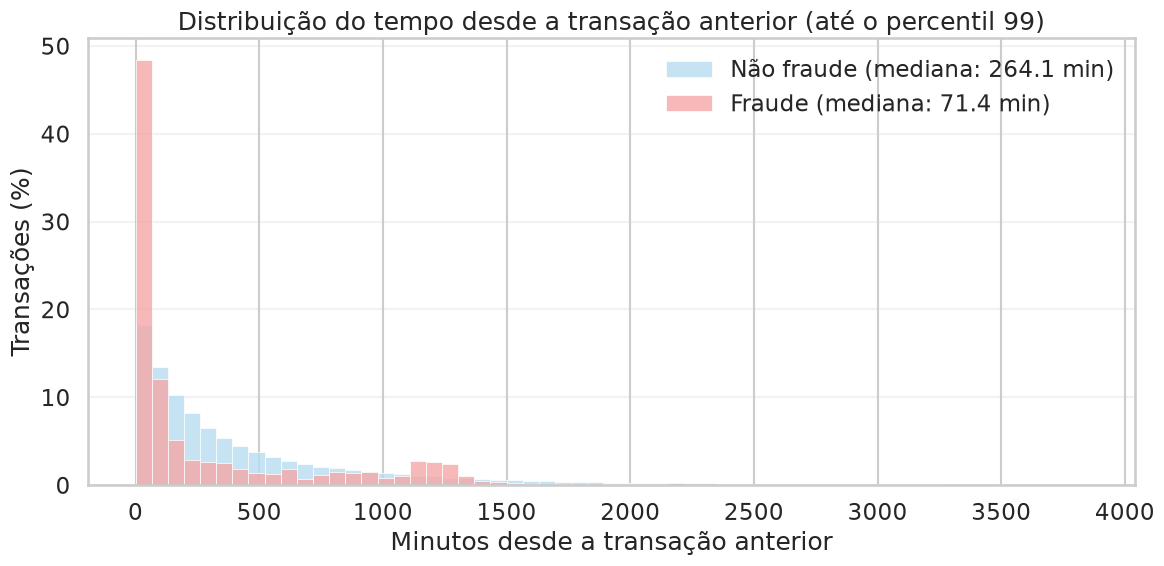

In [105]:
sns.set_theme(style="whitegrid", context="talk")

upper = raw["minutes_since_prev_txn"].quantile(0.99)
bins = np.linspace(0, upper, 60)

fig, ax = plt.subplots(figsize=(12, 6))

palette = {
    "Não fraude": "#B8DDF2",  # light blue
    "Fraude": "#F4A7A7",      # light red
}

for fraud_value, label in [(0, "Não fraude"), (1, "Fraude")]:
    values = raw.loc[raw["is_fraud"].eq(fraud_value), "minutes_since_prev_txn"]
    median_value = values.median()
    sns.histplot(
        x=values,
        bins=bins,
        stat="percent",
        color=palette[label],
        alpha=0.8,
        edgecolor="white",
        linewidth=0.5,
        label=f"{label} (mediana: {median_value:.1f} min)",
        ax=ax,
        
    )

ax.set_title("Distribuição do tempo desde a transação anterior (até o percentil 99)")
ax.set_xlabel("Minutos desde a transação anterior")
ax.set_ylabel("Transações (%)")
ax.grid(axis="y", alpha=0.25)
ax.legend(frameon=False)

plt.tight_layout()
plt.show()

A taxa de fraude cresce com o número de transações do cliente na hora anterior: fraudes tendem a vir em sequência. Notas-e também um leva aumento na taxa de fraude no dia seguinte e no mesmo período (pico em torno de 1200 min)

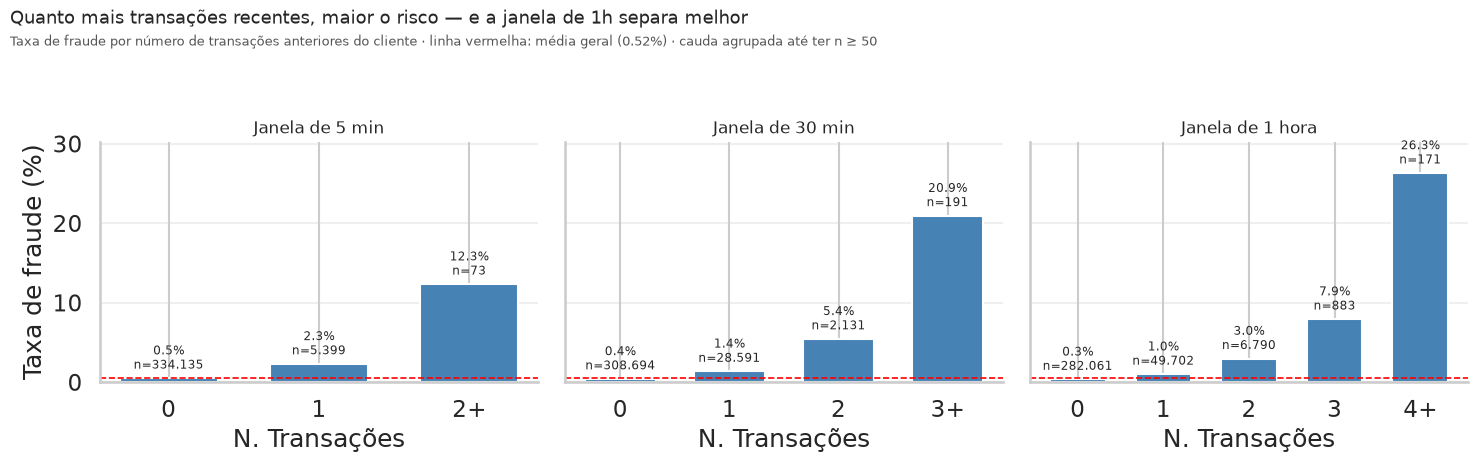

In [106]:
indicators = {"txns_prev_5min": "5 min", "txns_prev_30min": "30 min", "txns_prev_1h": "1 hora"}
MIN_N = 50  # agrupa a cauda até a última faixa ter pelo menos 50 transações
overall_rate_pct = raw["is_fraud"].mean() * 100


def tail_cap(counts: pd.Series, min_n: int) -> int:
    """Maior k tal que as faixas >= k somadas têm pelo menos min_n transações."""
    tail = counts.sort_index(ascending=False).cumsum()
    return int(tail[tail >= min_n].index.max())


fig, axes = plt.subplots(1, 3, figsize=(15, 4.8), sharey=True)

for ax, (col, label) in zip(axes, indicators.items()):
    cap = tail_cap(raw[col].value_counts(), MIN_N)
    summary = (raw.groupby(raw[col].clip(upper=cap))["is_fraud"]
                  .agg(n="size", taxa="mean"))
    pct = summary["taxa"] * 100
    x = np.arange(len(summary))

    ax.bar(x, pct, color="steelblue", width=0.65)
    ax.axhline(overall_rate_pct, color="red", ls="--", lw=1.2)

    for xi, (p, n) in enumerate(zip(pct, summary["n"])):
        ax.annotate(f"{p:.1f}%\nn={n:,}".replace(",", "."), (xi, p), xytext=(0, 4),
                    textcoords="offset points", ha="center", va="bottom", fontsize=8.5)

    ax.set_xticks(x, [f"{k}+" if k == cap else str(k) for k in summary.index])
    ax.set_title(f"Janela de {label}", fontsize=12)
    ax.set_xlabel("N. Transações")
    ax.grid(axis="y", alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)

axes[0].set_ylabel("Taxa de fraude (%)")
axes[0].margins(y=0.15)
fig.suptitle("Quanto mais transações recentes, maior o risco — e a janela de 1h separa melhor",
             fontsize=13, x=0.01, ha="left")
fig.text(0.01, 0.905,
         f"Taxa de fraude por número de transações anteriores do cliente · "
         f"linha vermelha: média geral ({overall_rate_pct:.2f}%) · cauda agrupada até ter n ≥ {MIN_N}",
         fontsize=9, color="#555", ha="left")
plt.tight_layout(rect=(0, 0, 1, 0.9))
plt.show()

---

## Comportamento de valor do cliente

Compara o valor da transação com o histórico do cliente:
* **30 dias anteriores:** razão para a média e para a mediana e z-score do valor
* **24 horas anteriores:** soma do valor transacionado e número de transações de valor alto (> R$ 200), para capturar rajadas de compras altas

Mesma regra das features de velocidade: só entram transações com timestamp estritamente anterior.

In [107]:
def add_customer_amount_features(
    df: pd.DataFrame,
    customer_col: str = "customer_id",
    amount_col: str = "amount",
    time_col: str = "created_at",
    high_amount: float = 200.0,
) -> pd.DataFrame:
    """
    Calcula features de valor por cliente usando apenas transações anteriores.

    Features:
        - amount_to_customer_mean_ratio_30d
        - amount_to_customer_median_ratio_30d
        - amount_zscore_customer_30d
        - amt_sum_prev_24h
        - n_high_prev_24h

    Janelas: [timestamp - janela, timestamp)
    """
    result = df.copy()
    stats = []

    for _, group in result.groupby(customer_col, sort=False):
        ordered = group.sort_values(time_col, kind="stable")
        amount = pd.Series(ordered[amount_col].to_numpy(dtype=float), index=ordered[time_col])

        window_30d = amount.rolling("30D", closed="left")
        window_24h = amount.rolling("24h", closed="left")
        high_24h = amount.gt(high_amount).astype(float).rolling("24h", closed="left")

        stats.append(pd.DataFrame(
            {
                "mean_30d": window_30d.mean().to_numpy(),
                "median_30d": window_30d.median().to_numpy(),
                "std_30d": window_30d.std().to_numpy(),
                "amt_sum_prev_24h": window_24h.sum().fillna(0).to_numpy(),
                "n_high_prev_24h": high_24h.sum().fillna(0).to_numpy(),
            },
            index=ordered.index,
        ))

    stats = pd.concat(stats).reindex(result.index)
    amount = result[amount_col]

    result["amount_to_customer_mean_ratio_30d"] = amount / stats["mean_30d"]
    result["amount_to_customer_median_ratio_30d"] = amount / stats["median_30d"]
    result["amount_zscore_customer_30d"] = (amount - stats["mean_30d"]) / stats["std_30d"]
    result["amt_sum_prev_24h"] = stats["amt_sum_prev_24h"]
    result["n_high_prev_24h"] = stats["n_high_prev_24h"].astype(int)

    return result

In [108]:
raw = add_customer_amount_features(raw)

amount_behavior_cols = [
    "amount_to_customer_mean_ratio_30d",
    "amount_to_customer_median_ratio_30d",
    "amount_zscore_customer_30d",
    "amt_sum_prev_24h",
    "n_high_prev_24h",
]



Observando o comparativo das estatísticas por cliente razao do amount por média ou pela mediana, ou o desvio (z-score) com relação ao comportamento dos últimos 30 dias, vê-se um comportamento similar acumulando fraudes nos extremos. Para uso em um modelo preditivo, o comportamento da mediana parece mais adequada, por comportar-se de maneira monotônica em quase todo o espectro (apenas com um pequeno valor na borda em 3%)



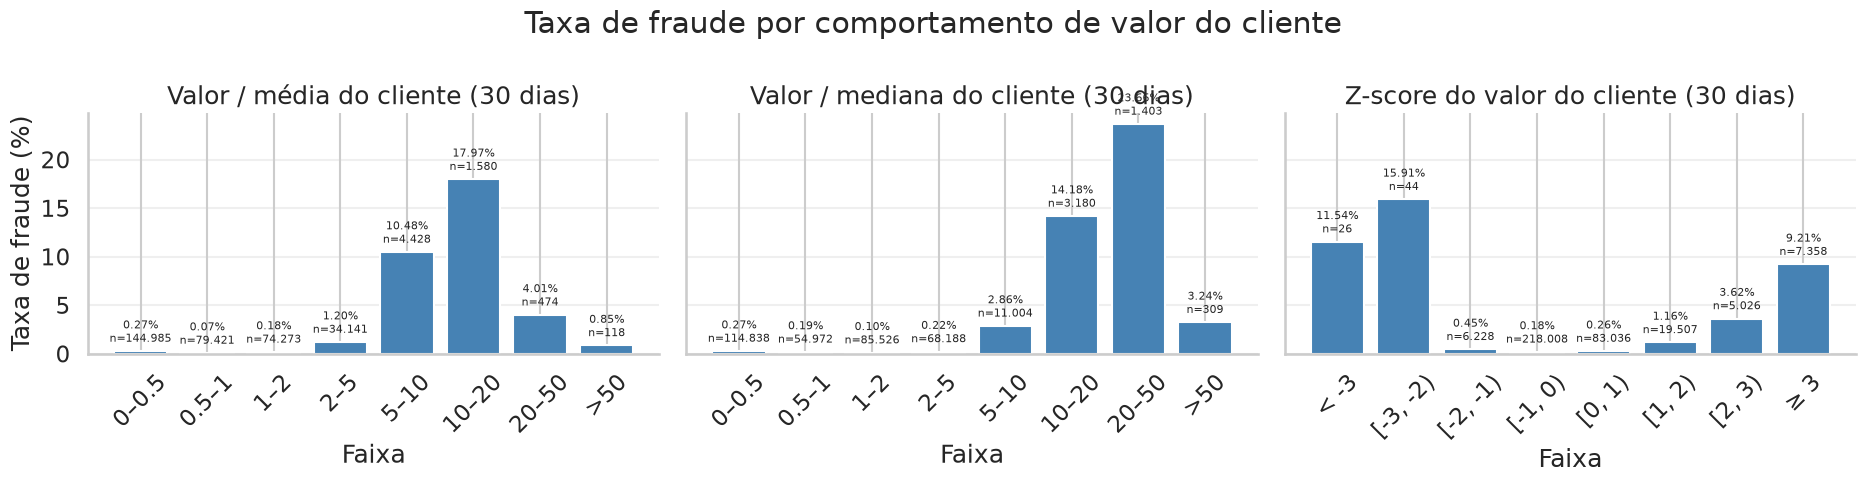

{'mean_ratio':    faixa  n_txns  n_frauds  fraud_rate  fraud_rate_pct
 0  0–0.5  144985       395    0.002724        0.272442
 1  0.5–1   79421        56    0.000705        0.070510
 2    1–2   74273       135    0.001818        0.181762
 3    2–5   34141       410    0.012009        1.200902
 4   5–10    4428       464    0.104788       10.478771
 5  10–20    1580       284    0.179747       17.974684
 6  20–50     474        19    0.040084        4.008439
 7    >50     118         1    0.008475        0.847458,
 'median_ratio':    faixa  n_txns  n_frauds  fraud_rate  fraud_rate_pct
 0  0–0.5  114838       313    0.002726        0.272558
 1  0.5–1   54972       102    0.001855        0.185549
 2    1–2   85526        88    0.001029        0.102893
 3    2–5   68188       153    0.002244        0.224380
 4   5–10   11004       315    0.028626        2.862595
 5  10–20    3180       451    0.141824       14.182390
 6  20–50    1403       332    0.236636       23.663578
 7    >50     309

In [109]:
ratio_bins = [0, 0.5, 1, 2, 5, 10, 20, 50, np.inf]
ratio_labels = ["0–0.5", "0.5–1", "1–2", "2–5", "5–10", "10–20", "20–50", ">50"]

zscore_bins = [-np.inf, -3, -2, -1, 0, 1, 2, 3, np.inf]
zscore_labels = ["< -3", "[-3, -2)", "[-2, -1)", "[-1, 0)", "[0, 1)", "[1, 2)", "[2, 3)", "≥ 3"]

feature_specs = {
    "mean_ratio": (
        "amount_to_customer_mean_ratio_30d",
        ratio_bins,
        ratio_labels,
        "Valor / média do cliente (30 dias)",
    ),
    "median_ratio": (
        "amount_to_customer_median_ratio_30d",
        ratio_bins,
        ratio_labels,
        "Valor / mediana do cliente (30 dias)",
    ),
    "zscore": (
        "amount_zscore_customer_30d",
        zscore_bins,
        zscore_labels,
        "Z-score do valor do cliente (30 dias)",
    ),
}

amount_behavior_tables = {}

for key, (feature, feature_bins, feature_labels, title) in feature_specs.items():
    values = (
        pd.to_numeric(raw[feature], errors="coerce")
        .replace([np.inf, -np.inf], np.nan)
        .dropna()
    )

    plot_data = pd.DataFrame({
        "value": values,
        "is_fraud": raw.loc[values.index, "is_fraud"],
    })
    plot_data["faixa"] = pd.cut(
        plot_data["value"],
        bins=feature_bins,
        labels=feature_labels,
        include_lowest=True,
        right=False,
    )

    table = (
        plot_data.groupby("faixa", observed=False)["is_fraud"]
        .agg(n_txns="size", n_frauds="sum", fraud_rate="mean")
        .reindex(feature_labels)
        .reset_index()
    )
    table["fraud_rate_pct"] = table["fraud_rate"] * 100
    amount_behavior_tables[key] = table

    table.to_csv(f"{key}_fraud_rate_by_bin.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(19, 5), sharey=True)

for ax, (key, (_, _, _, title)) in zip(axes, feature_specs.items()):
    table = amount_behavior_tables[key]
    rates = table["fraud_rate_pct"].fillna(0)

    bars = ax.bar(table["faixa"].astype(str), rates, color="steelblue")
    for bar, rate, n in zip(bars, rates, table["n_txns"]):
        ax.annotate(
            f"{rate:.2f}%\nn={n:,}".replace(",", "."),
            (bar.get_x() + bar.get_width() / 2, bar.get_height()),
            xytext=(0, 4),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=8,
        )

    ax.set_title(title)
    ax.set_xlabel("Faixa")
    ax.tick_params(axis="x", rotation=45)
    ax.grid(axis="y", alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)

axes[0].set_ylabel("Taxa de fraude (%)")
fig.suptitle("Taxa de fraude por comportamento de valor do cliente")
plt.tight_layout()
plt.show()

amount_behavior_tables

Fazendo uma categoria simples em cima da razao amount/mediana em 5, temos uma potencial variável explicativa com um bom lift

In [110]:
raw['amount_to_customer_median_ratio_30d_gt_5'] = np.where(raw['amount_to_customer_median_ratio_30d'] > 5, 1, 0)

In [111]:
iv_woe_category(raw,'amount_to_customer_median_ratio_30d_gt_5', 'is_fraud' )

is_fraud,n_legit,n_fraud,n_txns,pct_population,fraud_rate,lift,WOE,IV
amount_to_customer_median_ratio_30d_gt_5,,,,,,,,
1,14784,1108,15892,0.046795,0.069721,13.287098,2.653662,1.533661
0,323041,674,323715,0.953205,0.002082,0.396795,-0.927331,0.535943


---

# Transações de alto valor em janela recente (24h)

Avalindo o volume de transações no dia de anterior de valor elevado tem-se uma variável combinada trazendo os dois cenários que foi feita nessa análise.
Transações de fraude têm valor muito acima do padrão recente do cliente, e o número de compras de valor alto nas 24 h anteriores separa bem os dois grupos: uma sequência de compras altas é um forte sinal de fraude.

In [112]:
raw.groupby(raw["n_high_prev_24h"].clip(upper=5))["is_fraud"].agg(
    n_txns="count",
    n_frauds="sum",
    fraud_rate="mean",
)

,n_txns,n_frauds,fraud_rate
n_high_prev_24h,,,
0,282171,254,0.000900
1,46055,302,0.006557
2,8157,288,0.035307
3,2058,306,0.148688
4,629,246,0.391097
5,537,386,0.718808


Gerando uma flag (caso cliente tenha realizado mais de uma transação noturna de alto valor)

In [113]:
raw["n_high_prev_24h_gt_2"] = np.where(raw['n_high_prev_24h'] > 2 , 1, 0)

In [114]:
iv_woe_category(raw,'n_high_prev_24h_gt_2', 'is_fraud' )

is_fraud,n_legit,n_fraud,n_txns,pct_population,fraud_rate,lift,WOE,IV
n_high_prev_24h_gt_2,,,,,,,,
1,2286,938,3224,0.009493,0.290943,55.446832,4.353739,2.262167
0,335539,844,336383,0.990507,0.002509,0.478165,-0.740517,0.384766


---

# Valor transacionado nas últimas 24 horas

Por fim, traz-se uma análise semelhante a seção anterior, considerando a volume transacionado na janela de 24h. Nota-se novamente o padrão de baixo volume para transações legítimas, ao passso que transações legítimas apresentam um valor consistentemente mais elevado.
um corte em 600 reais no acumulado parece separar bem as transações fraudulentas, mas esbarraria no caso de fricção de cliente da regra fria que foi discutida inicialmente, (impacto negativo em bons clientes)

In [115]:
amt_sum_prev_24h_describe = (
    raw.groupby("is_fraud")["amt_sum_prev_24h"]
    .describe(percentiles=[0.25, 0.50, 0.75, 0.95, 0.99, 0.995, 0.999])
    .rename(index={0: "Não fraude", 1: "Fraude"})
)

amt_sum_prev_24h_describe

,count,mean,std,min,25%,50%,75%,95%,99%,99.5%,99.9%,max
is_fraud,,,,,,,,,,,,
Não fraude,337825.0,284.322233,421.691482,0.0,69.93,181.870,365.1200,893.010,1676.2332,2157.7904,3988.74736,29773.37
Fraude,1782.0,1965.241987,1586.933577,0.0,645.31,1667.075,2985.8675,4971.034,6453.5189,6894.3016,8420.20463,9671.12


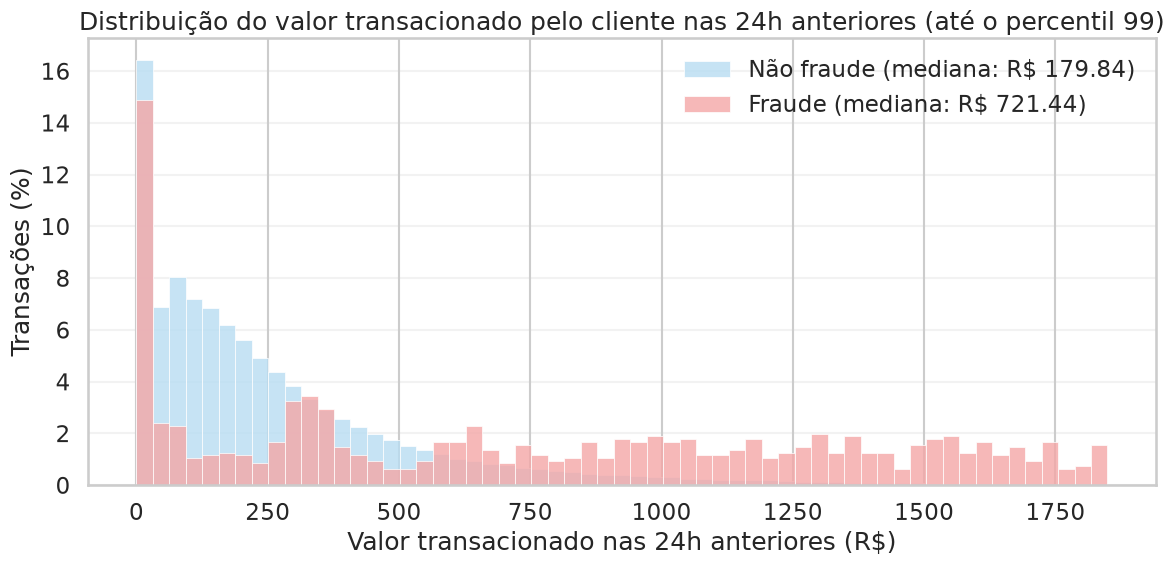

In [116]:
upper_amt_sum_24h = raw["amt_sum_prev_24h"].quantile(0.99)
bins_amt_sum_24h = np.linspace(0, upper_amt_sum_24h, 60)

fig_amt_sum_24h, ax_amt_sum_24h = plt.subplots(figsize=(12, 6))

for fraud_value, label in [(0, "Não fraude"), (1, "Fraude")]:
    values = raw.loc[
        raw["is_fraud"].eq(fraud_value)
        & raw["amt_sum_prev_24h"].le(upper_amt_sum_24h),
        "amt_sum_prev_24h",
    ]
    median_value = values.median()

    sns.histplot(
        x=values,
        bins=bins_amt_sum_24h,
        stat="percent",
        color=palette[label],
        alpha=0.8,
        edgecolor="white",
        linewidth=0.5,
        label=f"{label} (mediana: R$ {median_value:.2f})",
        ax=ax_amt_sum_24h,
    )

ax_amt_sum_24h.set_title("Distribuição do valor transacionado pelo cliente nas 24h anteriores (até o percentil 99)")
ax_amt_sum_24h.set_xlabel("Valor transacionado nas 24h anteriores (R$)")
ax_amt_sum_24h.set_ylabel("Transações (%)")
ax_amt_sum_24h.grid(axis="y", alpha=0.25)
ax_amt_sum_24h.legend(frameon=False)

plt.tight_layout()
plt.show()

In [117]:
raw['amt_sum_prev_24h_gt_600'] = np.where(raw['amt_sum_prev_24h'] > 600, 1, 0)

In [118]:
iv_woe_category(raw, 'amt_sum_prev_24h_gt_600', 'is_fraud')

is_fraud,n_legit,n_fraud,n_txns,pct_population,fraud_rate,lift,WOE,IV
amt_sum_prev_24h_gt_600,,,,,,,,
1,38396,1364,39760,0.117077,0.034306,6.537880,1.907055,1.242686
0,299429,418,299847,0.882923,0.001394,0.265672,-1.328724,0.865830


---

In [119]:
raw.columns

Index(['created_at', 'store_name', 'vertical', 'amount', 'device',
       'card_brand', 'city', 'state', 'lat', 'long', 'city_population', 'job',
       'date_of_birth', 'store_lat', 'store_long', 'is_fraud', 'cohort', 'day',
       'txn_id', 'high_amount', 'hour', 'night', 'risk_vertical', 'age',
       'distance_km', 'customer_id', 'store_id', 'minutes_since_prev_txn',
       'txns_prev_5min', 'txns_prev_30min', 'txns_prev_1h',
       'amount_to_customer_mean_ratio_30d',
       'amount_to_customer_median_ratio_30d', 'amount_zscore_customer_30d',
       'amt_sum_prev_24h', 'n_high_prev_24h',
       'amount_to_customer_median_ratio_30d_gt_5', 'n_high_prev_24h_gt_2',
       'amt_sum_prev_24h_gt_600'],
      dtype='str')

## Export

Base usada na modelagem (notebook 2): identificadores, target, vertical e features históricas do cliente. As variáveis de recategorização discutidas aqui serão recriadas no notebook de modelagem.

In [ ]:
export_cols = [
    "created_at",
    "txn_id",
    "customer_id",
    "amount",
    "vertical",
    "is_fraud",
    "txns_prev_1h",
    "amount_to_customer_median_ratio_30d",
    "n_high_prev_24h"

]

raw[export_cols].to_csv("../data/nuvem_fraud_dataset_pos_eda.csv", sep=";", index=False)
raw[export_cols].shape



(339607, 9)